# C — Random forest and MLP
## tl;dr
This executed companion reads the completed training experiment and independently reproduces validation predictions from saved pipelines. It does not silently rerun the hyperparameter search or evaluate test.

## Context & Methods
Random forest averages randomized bootstrap trees to reduce variance, at the cost of a larger and less transparent model. The MLP learns nonlinear representations with ReLU hidden layers and a sigmoid output, using weighted cross-entropy, L2 regularization and Adam; scaling, initialization and convergence matter.

### Key Assumptions
Same fixed train folds, AP selection, and fold-local balanced weights for all families. Validation metrics use p≥0.5 and are development diagnostics. Three-fold SD is not a confidence interval. D chooses thresholds and conducts the final test. Total search: 36 configurations across four families, 108 base CV fits.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from src.data import load_partition, audit_data
from src.metrics import binary_metrics
import joblib
EXPERIMENT = ROOT / 'results/experiment'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

## Data
The original 11 fields enter an importable pipeline; exact `pdays` becomes prior-contact status. Scaling is used for LR/MLP.
No learned transformation is fitted outside each CV training subset.

In [2]:
X_val,y_val=load_partition('val')
print('Validation records:',len(y_val),'(not final test)')

Validation records: 9042 (not final test)


### Inspect the actual model constructor and search space

In [3]:
from src.models import search_configs,build_model
from src.training import fit_candidate
import inspect
names=['random_forest', 'mlp']
for name in names:
    print(name)
    display(pd.DataFrame([{k: ('None' if v is None else v) for k,v in cfg.items()} for cfg in search_configs(name)]))
print(inspect.getsource(build_model))

random_forest


,max_depth,min_samples_leaf,weight
0,10,20,None
1,10,20,balanced
2,10,5,None
3,10,5,balanced
4,None,20,None
5,None,20,balanced
6,None,5,None
7,None,5,balanced


mlp


,hidden_layer_sizes,alpha,weight
0,"(32,)",0.0100,None
1,"(32,)",0.0100,balanced
2,"(32,)",0.0001,None
3,"(32,)",0.0001,balanced
4,"(64, 32)",0.0100,None
5,"(64, 32)",0.0100,balanced
6,"(64, 32)",0.0001,None
7,"(64, 32)",0.0001,balanced


def build_model(name, config, *, iteration_cap=None):
    params = {k: v for k, v in config.items() if k != 'weight'}
    if name == 'logistic_regression':
        model = LogisticRegression(solver='lbfgs', max_iter=2000, random_state=42, **params)
    elif name == 'decision_tree':
        model = DecisionTreeClassifier(criterion='gini', random_state=42, **params)
    elif name == 'random_forest':
        model = RandomForestClassifier(n_estimators=200, max_features='sqrt', bootstrap=True,
                                       random_state=42, n_jobs=1, **params)
    elif name == 'mlp':
        model = MLPClassifier(activation='relu', solver='adam', learning_rate_init=.001,
                              batch_size=256, early_stopping=False, max_iter=iteration_cap or 300,
                              tol=1e-4, n_iter_no_change=20, random_state=42, **params)
    elif name == 'dummy':
        model = DummyClassifier(strategy='prior')
    else:
        raise ValueError(name)
    return P

### Reproduce training explicitly
From the project root with the supplied environment:
```powershell
.venv\Scripts\python.exe scripts/train.py --output results/rerun --jobs 2
```
The output directory must be new. This command reruns all fixed configurations and records every fold, warning and refit. It produces no test predictions or performance metrics; the source CSV is read for structural checks.
Below, the completed `results/experiment` is inspected to keep notebook execution fast and deterministic.

## Results
### Selected parameters and training-fold scores

In [4]:
metadata={}
for name in names:
    metadata[name]=json.loads((EXPERIMENT/name/'model_metadata.json').read_text(encoding='utf-8'))
    print(name,metadata[name]['selected_params'])
    table=pd.read_csv(EXPERIMENT/name/'cv_candidates.csv')
    display(table[['config_id','mean_average_precision','std_average_precision','mean_train_ap','unconverged_folds']].rename(columns={
        'mean_average_precision':'CV AP mean','std_average_precision':'CV AP SD',
        'mean_train_ap':'Train AP','unconverged_folds':'Unconverged folds'}).round(5))

random_forest {'max_depth': None, 'min_samples_leaf': 20, 'weight': 'balanced'}


,config_id,CV AP mean,CV AP SD,Train AP,Unconverged folds
0,0,0.35767,0.00871,0.40925,0
1,1,0.35732,0.00750,0.41070,0
2,2,0.35723,0.01092,0.45317,0
3,3,0.35769,0.00951,0.45393,0
4,4,0.35772,0.01074,0.42506,0
5,5,0.35881,0.00854,0.42984,0
6,6,0.35094,0.01157,0.57240,0
7,7,0.35037,0.01280,0.58066,0


mlp {'hidden_layer_sizes': [32], 'alpha': 0.01, 'weight': None}


,config_id,CV AP mean,CV AP SD,Train AP,Unconverged folds
0,0,0.33267,0.01523,0.42048,0
1,1,0.31496,0.01326,0.42192,0
2,2,0.33113,0.00604,0.42719,0
3,3,0.31808,0.01141,0.42342,0
4,4,0.24592,0.01884,0.66031,1
5,5,0.24755,0.01084,0.61083,1
6,6,0.24095,0.00992,0.69051,3
7,7,0.24592,0.00890,0.63388,1


### Reload and verify all validation predictions

In [5]:
metric_rows=[]
for name in names:
    model=joblib.load(EXPERIMENT/name/'pipeline.joblib')
    with threadpool_limits(limits=1):
        p=model.predict_proba(X_val)[:,1]
    saved=pd.read_csv(EXPERIMENT/name/'validation_predictions.csv')
    np.testing.assert_array_equal(saved.row_id.to_numpy(),X_val.index.to_numpy())
    np.testing.assert_array_equal(saved.y_true.to_numpy(),y_val.to_numpy())
    np.testing.assert_allclose(saved.p_yes,p,rtol=1e-12,atol=1e-12)
    metric_rows.append({'model':name,**binary_metrics(y_val,p)})
metrics=pd.DataFrame(metric_rows).set_index('model')
display(metrics[['average_precision','roc_auc','precision','recall','f1','accuracy']].rename(columns={
    'average_precision':'AP','roc_auc':'ROC-AUC','precision':'Precision','recall':'Recall','f1':'F1','accuracy':'Accuracy'}).round(5))
display(metrics[['tn','fp','fn','tp','brier_score','log_loss']].rename(columns={
    'brier_score':'Brier score','log_loss':'Log loss'}).round(5))
print('All saved validation rows, labels and probabilities reproduced.')

,AP,ROC-AUC,Precision,Recall,F1,Accuracy
model,,,,,,
random_forest,0.38651,0.74381,0.29077,0.55955,0.38268,0.78876
mlp,0.37719,0.73759,0.68914,0.17391,0.27774,0.89416


,tn,fp,fn,tp,Brier score,Log loss
model,,,,,,
random_forest,6540,1444,466,592,0.17652,0.54096
mlp,7901,83,874,184,0.08756,0.30921


All saved validation rows, labels and probabilities reproduced.


### Training versus CV tuning diagnostics

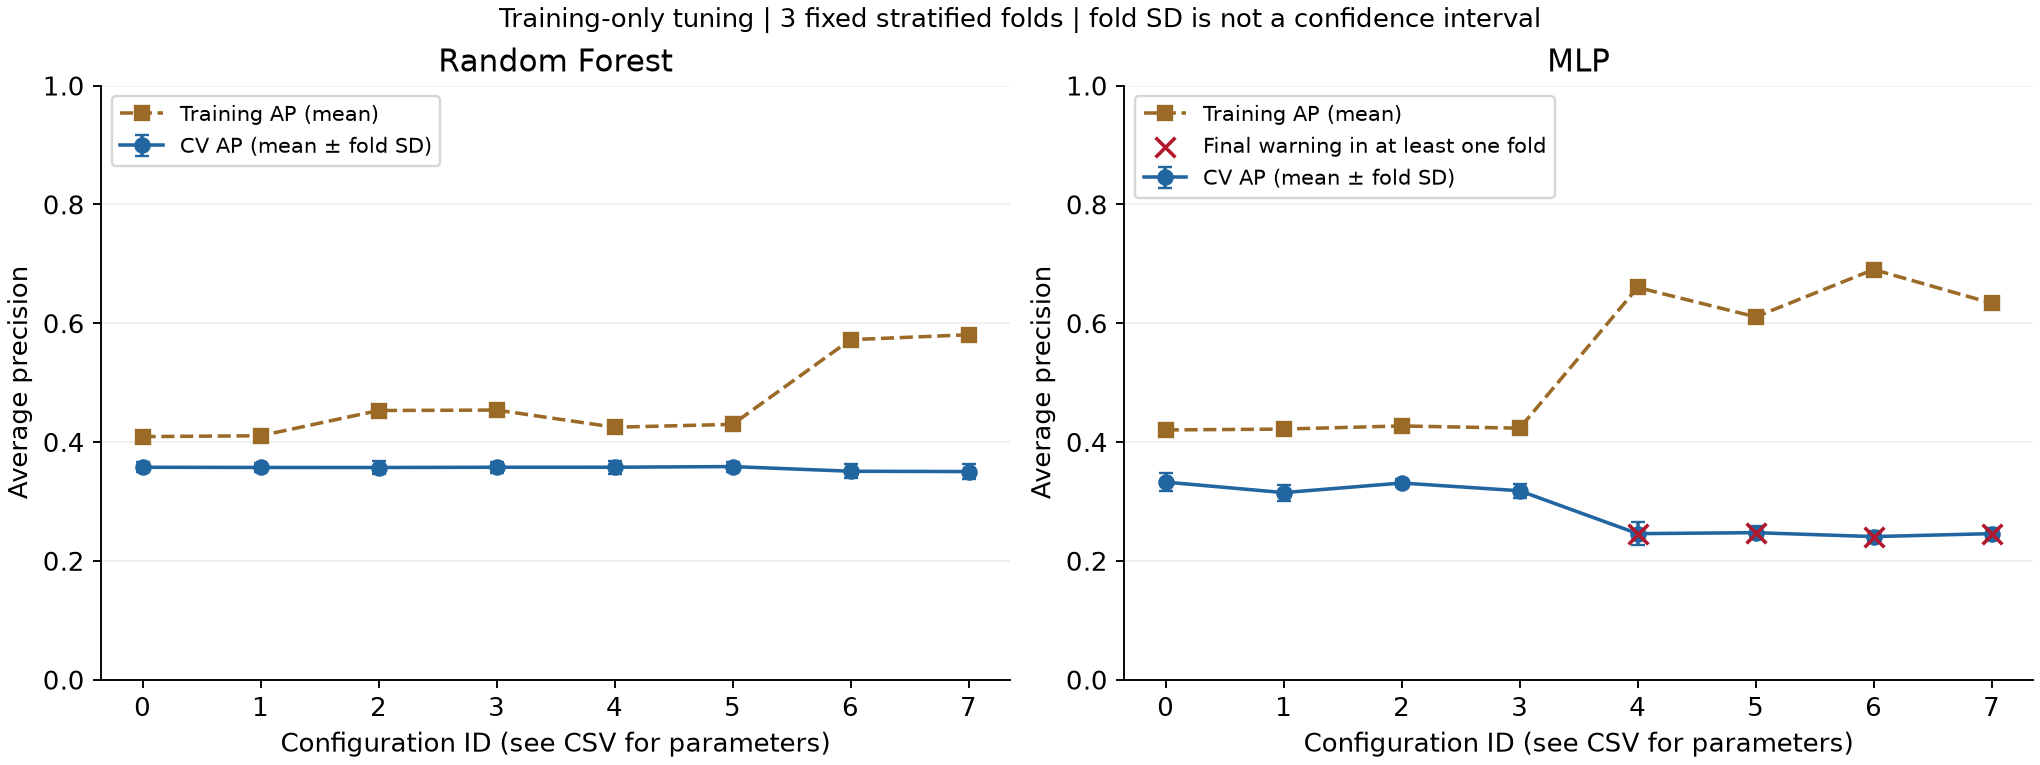

In [6]:
from src.model_plots import generate_model_plots
generate_model_plots(EXPERIMENT)
display(Image(filename=str(EXPERIMENT/'figures/C_advanced_tuning.png')))

### MLP convergence
Internal accuracy-based early stopping is disabled. Every capped fit with ConvergenceWarning restarts once at 600 epochs, with the same seed. The trace is a training objective, not held-out AP.

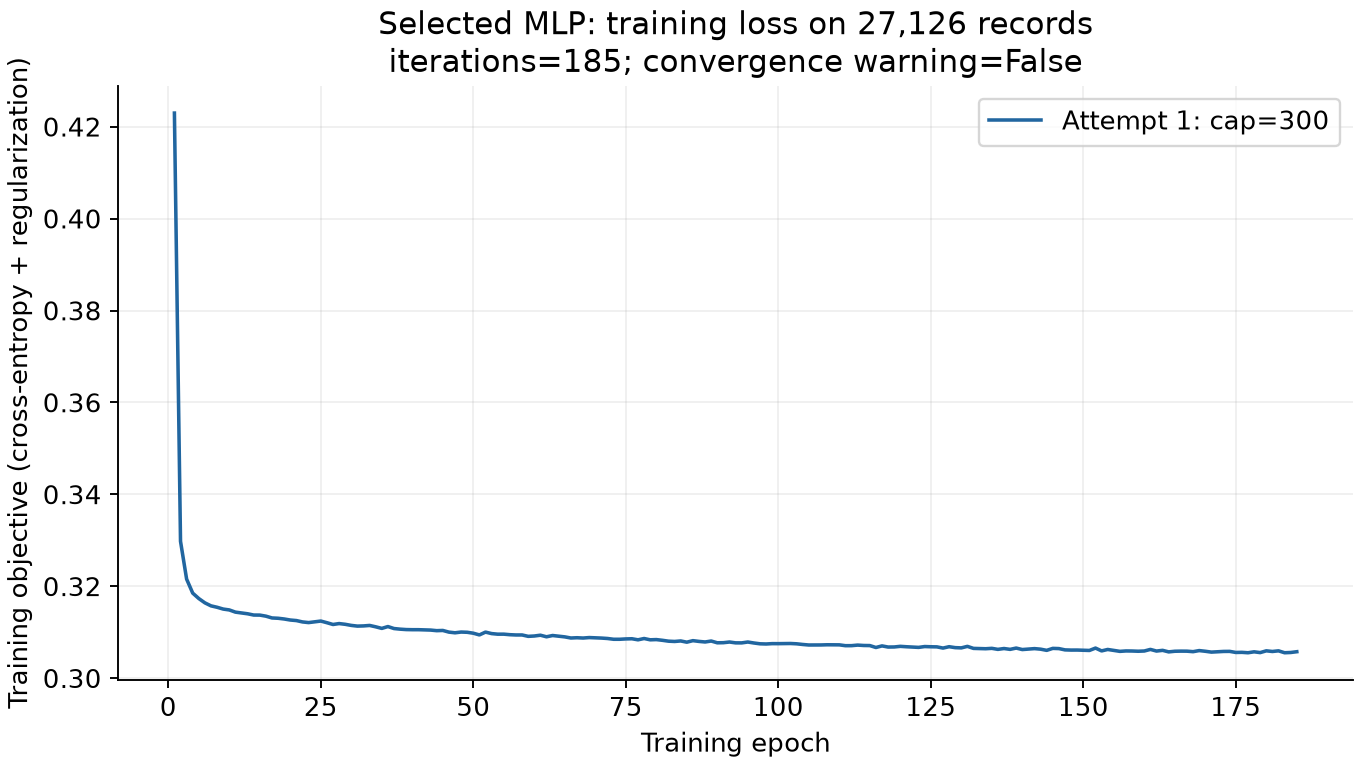

MLP CV folds: 24; additional retry fits: 21; final unconverged folds: 6


,config_id,fold_id,attempt_count,n_iter,final_convergence_warning
0,0,0,1,213,False
1,0,1,1,235,False
2,0,2,2,368,False


{'max_iter': 300, 'n_iter': 185, 'fit_seconds': 3.322797400003765, 'convergence_warning': False, 'warnings': []}


In [7]:
display(Image(filename=str(EXPERIMENT/'figures/MLP_training_loss.png')))
folds=pd.read_csv(EXPERIMENT/'mlp/cv_folds.csv')
print(f'MLP CV folds: {len(folds)}; additional retry fits: {int((folds.attempt_count-1).sum())}; final unconverged folds: {int(folds.final_convergence_warning.sum())}')
selected=folds[folds.config_id==metadata['mlp']['config_id']]
display(selected[['config_id','fold_id','attempt_count','n_iter','final_convergence_warning']])
for attempt in metadata['mlp']['refit_attempts']:
    print({k:v for k,v in attempt.items() if k!='loss_curve'})

## Takeaways
The tables show the results actually produced by the frozen experiment. A larger training-to-CV AP gap is evidence of overfitting under this protocol, not proof of future failure.
Weighted model outputs are not assumed to be calibrated probabilities; 0.5 is a comparison convention rather than an optimized business threshold.
The complete model and validation CSV are ready for D. D retains threshold selection, test evaluation, error analysis, feature importance and final cross-model conclusions.
中文交接：这里的成绩属于开发阶段；不要改名为测试集成绩，也不要据此补调参数。